# Modeling Supply Chain Resilience

## Background

Global supply chains face increasing disruption risks from geopolitical tensions, cyberattacks, natural disasters, and operational incidents. 

Understanding how disruptions propagate across multi-tier supplier networks and how mitigation strategies influence recovery time is critical for strategic decision-making.

## Objective

This project aims to analyze disruption impact, recovery dynamics, and mitigation effectiveness across industries, and to develop a resilience framework to support supply chain strategy.

## Key Questions

1. What factors drive financial and operational impact during disruptions?
2. Which response strategies are most effective in reducing recovery time?
3. How does supplier tier (Tier 1–4) influence vulnerability and cascading effects?

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/likithagedipudi/supply-chain-disruption-and-recovery-dataset/supply_chain_disruption_recovery.csv


In [2]:
file_path = "/kaggle/input/datasets/likithagedipudi/supply-chain-disruption-and-recovery-dataset/supply_chain_disruption_recovery.csv"

df = pd.read_csv(file_path)

df.head()

,disruption_id,disruption_type,industry,supplier_tier,supplier_region,supplier_size,has_backup_supplier,disruption_severity,production_impact_pct,revenue_loss_usd,response_type,response_time_days,partial_recovery_days,full_recovery_days,permanent_supplier_change
0,DIS-000001,Factory Incident,Pharmaceuticals,1,Asia-Pacific,Large,False,2,54.3,11376013.16,Customer Delay,14,3,59,False
1,DIS-000002,Cyber Attack,Electronics,2,Asia-Pacific,Medium,True,4,52.4,1199054.59,Alternative Supplier,1,29,97,True
2,DIS-000003,Port Congestion,Electronics,1,Asia-Pacific,Small,True,2,32.4,228848.77,Alternative Supplier,1,18,67,True
3,DIS-000004,Labor Strike,Electronics,2,Europe,Large,True,1,15.7,2257287.82,Alternative Supplier,1,18,36,False
4,DIS-000005,Geopolitical,Electronics,1,South America,Medium,True,2,32.9,965588.44,Alternative Supplier,7,11,61,True


## 2. Data Overview & Metric Definitions

This dataset contains 100,000 recorded supply chain disruption events across five industries, covering multi-tier supplier networks (Tier 1–4).

Before moving into impact and strategy analysis, I first examine the dataset structure and define the key metrics that will guide the evaluation framework.

### 2.1 Dataset Structure

The dataset includes:
- Structural attributes (industry, supplier tier, region, size)
- Disruption characteristics (type, severity)
- Impact indicators (production impact %, revenue loss)
- Response variables (response type, response time)
- Recovery outcomes (partial and full recovery days)
- Structural change signal (permanent supplier change)

### 2.2 Core Analytical Dimensions

To support strategic decision-making, I categorize variables into four analytical dimensions:

**1. Impact**
- `production_impact_pct`
- `revenue_loss_usd`

**2. Speed & Recovery**
- `response_time_days`
- `partial_recovery_days`
- `full_recovery_days`

**3. Structural Risk Factors**
- `supplier_tier`
- `supplier_region`
- `supplier_size`
- `has_backup_supplier`
- `disruption_severity`

**4. Strategic Response**
- `response_type`
- `permanent_supplier_change`

These definitions will guide subsequent impact modeling and resilience scoring.

In [3]:
data_dict = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.values,
    "Non-Null Count": df.notnull().sum().values
})

data_dict
df.shape

(100000, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   disruption_id              100000 non-null  object 
 1   disruption_type            100000 non-null  object 
 2   industry                   100000 non-null  object 
 3   supplier_tier              100000 non-null  int64  
 4   supplier_region            100000 non-null  object 
 5   supplier_size              100000 non-null  object 
 6   has_backup_supplier        100000 non-null  bool   
 7   disruption_severity        100000 non-null  int64  
 8   production_impact_pct      100000 non-null  float64
 9   revenue_loss_usd           100000 non-null  float64
 10  response_type              100000 non-null  object 
 11  response_time_days         100000 non-null  int64  
 12  partial_recovery_days      100000 non-null  int64  
 13  full_recovery_days         100

In [5]:
df.describe()

,supplier_tier,disruption_severity,production_impact_pct,revenue_loss_usd,response_time_days,partial_recovery_days,full_recovery_days
count,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000
mean,2.101210,2.497110,31.411037,2.522812e+06,4.067590,27.512140,75.841100
std,0.995056,1.083745,17.565837,5.533130e+06,4.712087,25.778973,56.911147
min,1.000000,1.000000,1.000000,1.000000e+04,1.000000,3.000000,8.000000
25%,1.000000,2.000000,18.400000,3.016020e+05,1.000000,10.000000,35.000000
50%,2.000000,2.000000,30.100000,8.754662e+05,2.000000,20.000000,61.000000
75%,3.000000,3.000000,42.900000,2.492971e+06,5.000000,37.000000,100.000000
max,4.000000,5.000000,100.000000,3.731310e+08,64.000000,337.000000,798.000000


### Initial Observations

- The average production impact is approximately 31%, suggesting substantial operational disruption.
- Average revenue loss exceeds $2.5M, with a highly skewed distribution.
- Mean full recovery time is approximately 76 days, with extreme cases reaching over 700 days.
- Supplier tiers range from Tier 1 to Tier 4, enabling multi-layer vulnerability analysis.

These descriptive statistics indicate significant variability in disruption impact and recovery dynamics, reinforcing the need for structured resilience evaluation.

## 3. Disruption Landscape

In this section, the overall disruption landscape is examined to understand how risks are distributed across industries, supplier tiers, and disruption types.

The objective is to identify structural exposure patterns before moving into impact and recovery analysis.

### 3.1 Distribution of Disruption Types

The frequency of each disruption type is analyzed to determine which risks occur most frequently across the dataset.

Understanding the disruption mix provides context for evaluating strategic mitigation priorities.

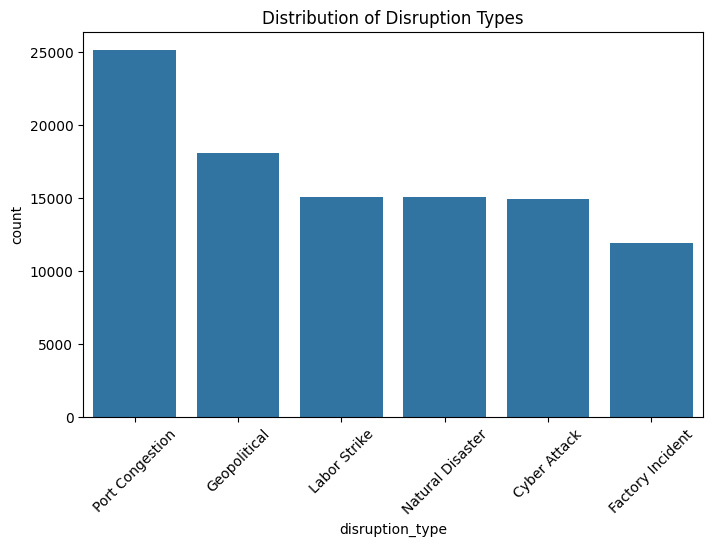

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(data=df, x="disruption_type", order=df["disruption_type"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Distribution of Disruption Types")
plt.show()

### Observations

Port congestion appears as the most frequently observed disruption type in the dataset, followed by geopolitical events. 

Operational disruptions such as labor strikes, natural disasters, and cyber attacks exhibit relatively comparable frequencies, while factory incidents are observed less frequently.

The distribution suggests that systemic logistics constraints and geopolitical instability represent persistent structural risks across supply networks, whereas factory-level incidents may represent more localized events.

### 3.2 Industry Exposure to Disruptions

Disruption events are further examined across industries to assess whether certain sectors experience disproportionate exposure.

Industry-level analysis helps identify sector-specific vulnerability patterns.

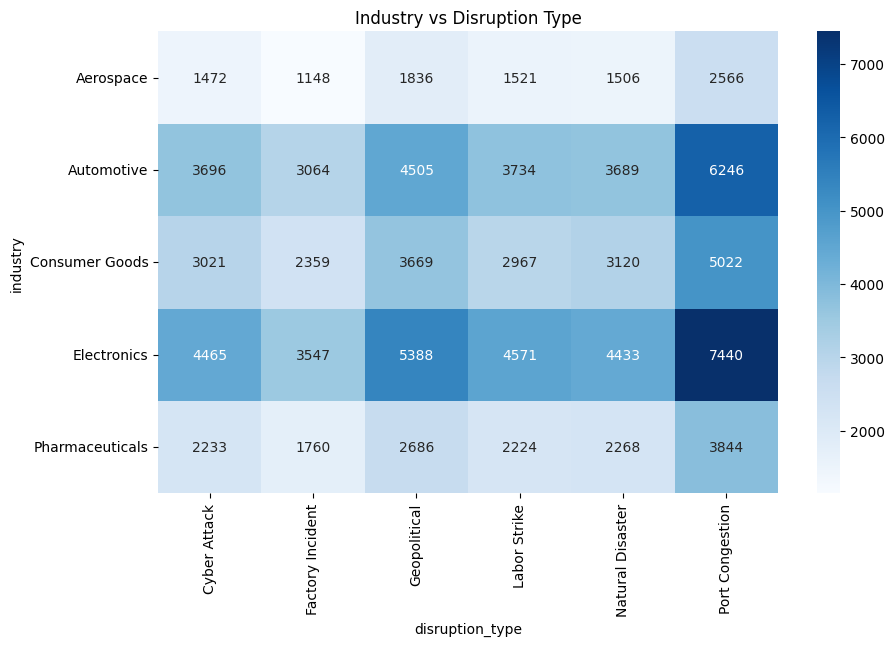

In [7]:
industry_disruption = pd.crosstab(df["industry"], df["disruption_type"])

plt.figure(figsize=(10,6))
sns.heatmap(industry_disruption, annot=True, fmt="d", cmap="Blues")
plt.title("Industry vs Disruption Type")
plt.show()

### Observations

Disruption exposure varies significantly across industries.

The Electronics and Automotive sectors exhibit the highest concentration of disruption events across nearly all disruption categories, particularly port congestion and geopolitical events.

In contrast, Aerospace and Pharmaceuticals show comparatively lower absolute disruption counts.

This pattern suggests that highly globalized and component-intensive industries may face elevated exposure to multi-source supply chain risks.

### 3.3 Supplier Tier Exposure

Disruptions are analyzed across supplier tiers (Tier 1–4) to evaluate whether upstream or downstream suppliers exhibit different exposure levels.

Tier-level analysis provides insight into cascading risk potential across supply networks.

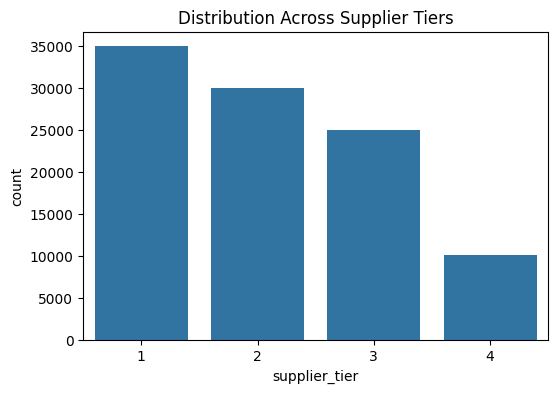

In [8]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="supplier_tier")
plt.title("Distribution Across Supplier Tiers")
plt.show()

### Observations

Disruptions are more frequently observed among Tier 1 and Tier 2 suppliers, with exposure declining in upstream tiers.

This distribution may reflect greater visibility and reporting of disruptions at direct supplier levels compared to deeper-tier suppliers.

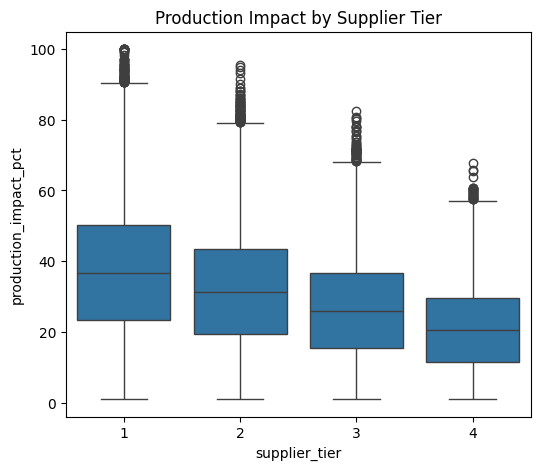

In [9]:
plt.figure(figsize=(6,5))
sns.boxplot(data=df, x="supplier_tier", y="production_impact_pct")
plt.title("Production Impact by Supplier Tier")
plt.show()

### Observations

Production impact decreases progressively from Tier 1 to Tier 4 suppliers.

Tier 1 disruptions exhibit the highest median and upper-range production impact, indicating direct operational exposure.

Upstream tiers (Tier 3–4), while still affected, demonstrate lower median impact levels.

This pattern suggests that disruptions closer to the focal firm generate stronger immediate operational consequences, whereas upstream shocks may propagate indirectly.

## 4. Impact Analysis: What Drives Losses?

In this section, the primary drivers of financial and operational losses are examined.

Rather than focusing solely on correlations, the objective is to identify structural risk drivers that materially increase disruption impact.

Both operational impact (production_impact_pct) and financial impact (revenue_loss_usd) are analyzed across severity levels, disruption types, industries, supplier tiers, and mitigation mechanisms.

### 4.1 Severity vs Operational and Financial Impact

Disruption severity is evaluated as a primary driver of operational and financial loss.

Both distribution patterns and mean differences are examined to assess whether higher severity levels are associated with disproportionately larger impacts.

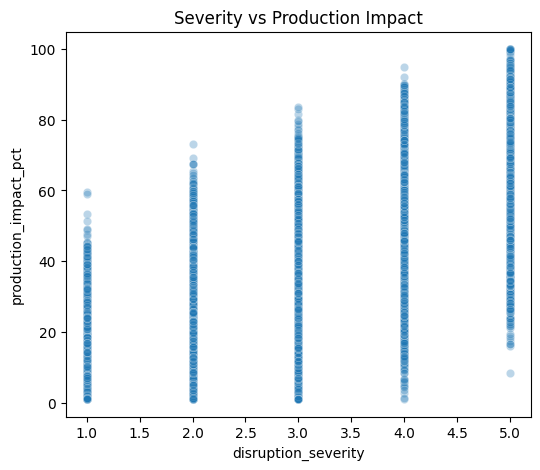

,production_impact_pct,revenue_loss_usd
disruption_severity,,
1,13.278666,1.085165e+06
2,25.123519,1.981936e+06
3,37.498514,3.035963e+06
4,50.065800,4.009187e+06
5,62.245318,5.052478e+06


In [10]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df, x="disruption_severity", y="production_impact_pct", alpha=0.3)
plt.title("Severity vs Production Impact")
plt.show()

severity_summary = df.groupby("disruption_severity")[["production_impact_pct","revenue_loss_usd"]].mean()
severity_summary

### 4.2 Impact by Disruption Type

Impact distributions are compared across disruption categories to determine whether certain disruption types generate disproportionately high losses.

Both operational and financial impacts are evaluated.

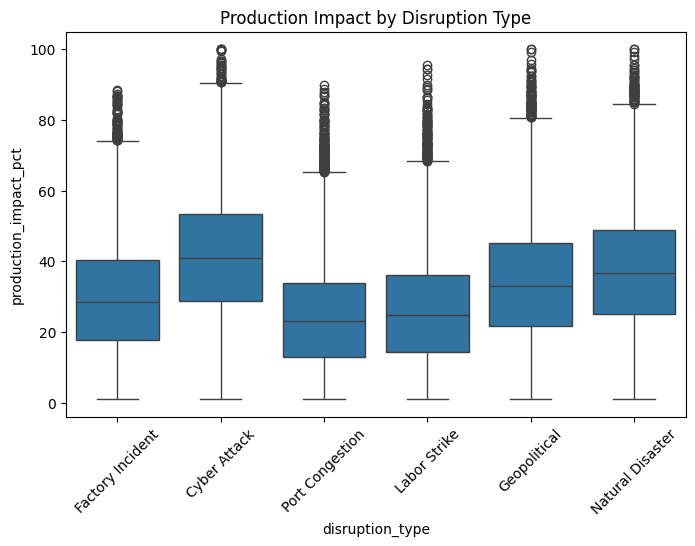

,production_impact_pct,revenue_loss_usd
disruption_type,,
Cyber Attack,41.311137,3.365434e+06
Natural Disaster,37.330374,3.039002e+06
Geopolitical,33.863255,2.691691e+06
Factory Incident,29.584812,2.359573e+06
Labor Strike,25.998095,2.033352e+06
Port Congestion,24.339000,1.963051e+06


In [11]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="disruption_type", y="production_impact_pct")
plt.xticks(rotation=45)
plt.title("Production Impact by Disruption Type")
plt.show()

type_summary = df.groupby("disruption_type")[["production_impact_pct","revenue_loss_usd"]].mean().sort_values("revenue_loss_usd", ascending=False)
type_summary

### 4.3 Industry-Level Loss Exposure

Financial and operational losses are analyzed across industries to assess whether structural industry characteristics influence impact magnitude.

In [12]:
industry_summary = df.groupby("industry")[["production_impact_pct","revenue_loss_usd"]].mean().sort_values("revenue_loss_usd", ascending=False)
industry_summary

,production_impact_pct,revenue_loss_usd
industry,,
Aerospace,31.410827,6.067862e+06
Pharmaceuticals,31.376444,3.664839e+06
Automotive,31.378375,2.432135e+06
Electronics,31.436922,1.871191e+06
Consumer Goods,31.438987,9.817942e+05


### 4.4 Supplier Tier Effects

Loss magnitude is evaluated across supplier tiers to determine whether upstream or downstream disruptions generate stronger financial and operational consequences.

In [13]:
tier_summary = df.groupby("supplier_tier")[["production_impact_pct","revenue_loss_usd"]].mean()
tier_summary

,production_impact_pct,revenue_loss_usd
supplier_tier,,
1,37.425394,2.960528e+06
2,31.978347,2.576283e+06
3,26.491974,2.167665e+06
4,21.022625,1.723125e+06


### 4.5 Mitigation Effect: Backup Supplier Presence

The buffering effect of backup suppliers is assessed by comparing impact levels between firms with and without backup suppliers.

This analysis evaluates whether redundancy mechanisms materially reduce disruption losses.

In [14]:
backup_summary = df.groupby("has_backup_supplier")[["production_impact_pct","revenue_loss_usd","full_recovery_days"]].mean()
backup_summary

,production_impact_pct,revenue_loss_usd,full_recovery_days
has_backup_supplier,,,
False,31.489562,2.112997e+06,90.301738
True,31.348264,2.850419e+06,64.281229


### 4.6 Impact Driver Summary

A consolidated summary of mean impact levels across key risk dimensions is presented to identify the strongest loss drivers.

### Observations

The analysis identifies several structural drivers of disruption impact across operational and financial dimensions.

First, disruption severity emerges as the strongest linear driver of both production impact and revenue loss. Mean production loss increases progressively from 13% at severity level 1 to over 62% at severity level 5, with financial losses rising proportionally. This confirms severity as the primary risk amplifier.

Second, disruption type materially influences impact magnitude. Cyber attacks and natural disasters generate the highest average operational and financial losses, suggesting that systemic and infrastructure-level shocks produce greater disruption than localized operational incidents such as port congestion or labor strikes.

Third, supplier tier proximity plays a significant role. Tier 1 suppliers exhibit the highest average production and revenue impact, with losses declining progressively toward upstream tiers. This indicates that disruptions closer to the focal firm produce more immediate operational consequences, while upstream shocks appear to attenuate across the network.

Fourth, industry-level differences are more pronounced in financial loss than in operational impact. While production impact remains relatively similar across industries (~31%), revenue loss varies significantly, with Aerospace and Pharmaceuticals exhibiting materially higher financial exposure. This suggests that value density and margin structure influence loss magnitude more than operational disruption alone.

Finally, the presence of backup suppliers does not significantly reduce immediate production impact; however, it substantially reduces full recovery time (approximately 90 days without backup vs 64 days with backup). This indicates that redundancy mechanisms function primarily as recovery accelerators rather than impact preventers.

Overall, severity level, disruption type, and supplier proximity emerge as the dominant impact drivers, while mitigation mechanisms primarily influence recovery duration rather than initial loss magnitude.


## 5. Recovery Dynamics: What Drives Faster Recovery?

In this section, recovery dynamics are analyzed to identify the structural drivers of resilience.

While Section 4 focused on loss magnitude, this section examines recovery speed and adjustment mechanisms.

Both response timing and recovery duration (partial and full) are evaluated across disruption characteristics, supply chain structure, and mitigation strategies.

### 5.1 Response Speed Distribution

The distribution of response_time_days is examined to understand how quickly firms initiate mitigation actions following disruption events.

Early response is evaluated as a potential resilience lever.

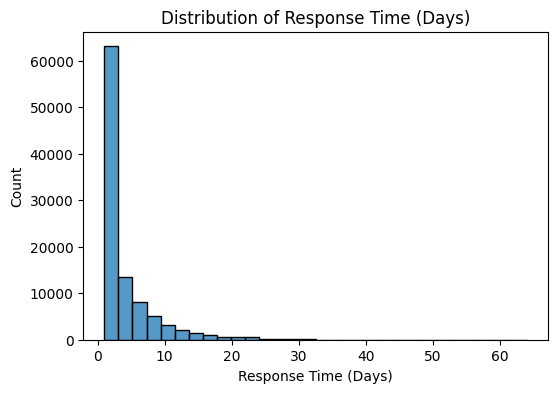

In [15]:
plt.figure(figsize=(6,4))
sns.histplot(df["response_time_days"], bins=30)
plt.title("Distribution of Response Time (Days)")
plt.xlabel("Response Time (Days)")
plt.show()

### 5.2 Partial vs Full Recovery Relationship

The relationship between partial_recovery_days and full_recovery_days is evaluated to assess whether early stabilization translates proportionally into faster full recovery.

This analysis provides insight into recovery trajectory dynamics.

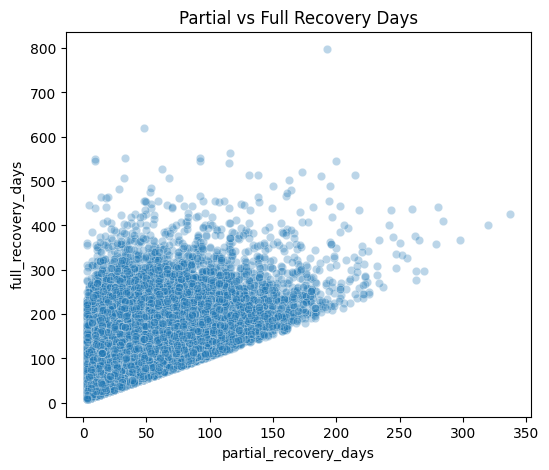

In [16]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df, x="partial_recovery_days", y="full_recovery_days", alpha=0.3)
plt.title("Partial vs Full Recovery Days")
plt.show()

### 5.3 Recovery by Disruption Type, Industry, and Supplier Tier

Full recovery duration is compared across disruption categories, industries, and supplier tiers to identify structural differences in resilience.

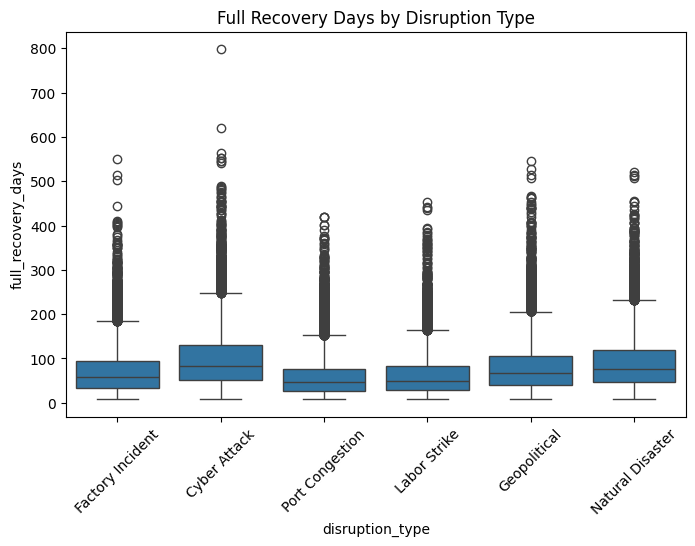

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="disruption_type", y="full_recovery_days")
plt.xticks(rotation=45)
plt.title("Full Recovery Days by Disruption Type")
plt.show()

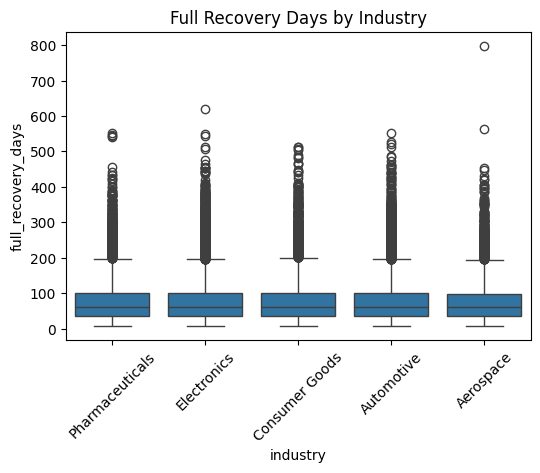

In [18]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="industry", y="full_recovery_days")
plt.xticks(rotation=45)
plt.title("Full Recovery Days by Industry")
plt.show()

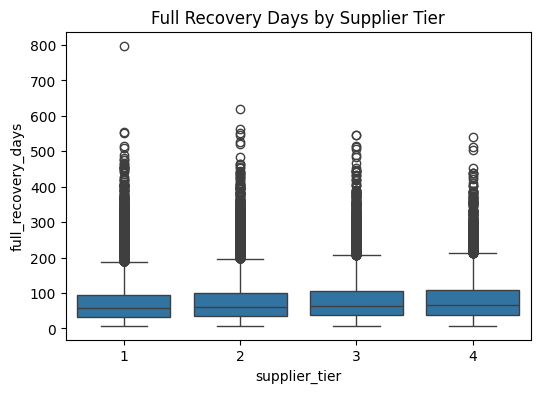

In [19]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="supplier_tier", y="full_recovery_days")
plt.title("Full Recovery Days by Supplier Tier")
plt.show()

### 5.4 Mitigation Effect: Backup Supplier and Recovery Speed

Recovery duration is compared between firms with and without backup suppliers to evaluate whether redundancy mechanisms accelerate recovery.

In [20]:
backup_recovery = df.groupby("has_backup_supplier")[
    ["response_time_days", "partial_recovery_days", "full_recovery_days"]
].mean()

backup_recovery

,response_time_days,partial_recovery_days,full_recovery_days
has_backup_supplier,,,
False,5.655900,30.830415,90.301738
True,2.797891,24.859503,64.281229


### 5.5 Permanent Supplier Change as Structural Adjustment Signal

The conditions under which permanent supplier changes occur are analyzed to determine whether severe or prolonged disruptions trigger long-term structural reconfiguration.

This analysis examines severity, recovery duration, and impact levels across cases with and without permanent supplier changes.

In [21]:
change_summary = df.groupby("permanent_supplier_change")[
    ["disruption_severity", "production_impact_pct", "revenue_loss_usd", "full_recovery_days"]
].mean()

change_summary

,disruption_severity,production_impact_pct,revenue_loss_usd,full_recovery_days
permanent_supplier_change,,,,
False,2.395163,30.021196,2.442223e+06,70.392915
True,2.821363,35.831568,2.779133e+06,93.169607


### Observation

The recovery analysis reveals several structural resilience patterns across response speed, recovery trajectory, and long-term adjustment behavior.

First, response time is **highly right-skewed**, with the majority of firms initiating mitigation actions within the first few days following disruption. This suggests that **initial response activation is generally rapid**, though a minority of cases exhibit significant delays.

Second, a strong positive relationship is observed between partial and full recovery duration. While early stabilization reduces immediate operational pressure, full recovery timelines extend substantially beyond partial recovery milestones. This indicates that **supply chain restoration is often nonlinear and subject to prolonged adjustment even after operations partially resume.**

Third, recovery duration varies meaningfully across disruption types. Cyber attacks and natural disasters exhibit longer median and upper-tail recovery periods, whereas port congestion and labor strikes demonstrate comparatively shorter recovery timelines. This suggests that **infrastructure-level and systemic shocks impose more persistent operational strain.**

Fourth, industry-level recovery differences are less pronounced than disruption-type differences. Recovery distributions appear broadly similar across industries, implying that **structural disruption characteristics may outweigh sector-specific factors in determining recovery duration**.

Fifth, supplier tier effects show moderate differentiation, with upstream tiers exhibiting slightly longer recovery medians. However, tier-based differences are smaller than those driven by disruption type.

Most notably, the presence of backup suppliers materially accelerates recovery. **Firms with backup suppliers exhibit significantly shorter response times**, partial recovery durations, and full recovery timelines (approximately 64 days vs 90 days without backup). This indicates that redundancy mechanisms function as recovery accelerators rather than impact preventers.

Finally, **permanent supplier changes are associated with higher disruption severity**, greater operational and financial loss, and substantially longer recovery duration. Cases involving permanent supplier changes exhibit full recovery periods exceeding 93 days on average, compared to approximately 70 days when no structural change occurs. This suggests that prolonged and severe disruptions increase the likelihood of structural supply network reconfiguration.

Overall, **resilience appears to be driven less by industry identity and more by disruption characteristics**, response speed, and redundancy mechanisms. Backup capacity and rapid response emerge as the most effective levers for accelerating recovery, while severe systemic disruptions are more likely to trigger long-term structural adjustment.

## 6. Strategy Effectiveness: Comparative Performance & Trade-offs

This section evaluates the relative effectiveness of different response strategies in mitigating disruption impact and accelerating recovery.

The analysis compares average recovery duration, financial loss, operational impact, and the rate of permanent supplier changes across response types.

Lower recovery time, lower financial loss, and lower production impact are interpreted as indicators of higher short-term effectiveness. However, the rate of permanent supplier change is examined separately, as it may signal either strategic adaptation or structural disruption.

### 6.1 Strategy Performance Overview

Mean performance metrics are computed for each response type, including:

- Average full recovery duration
- Average revenue loss
- Average production impact percentage
- Percentage of cases resulting in permanent supplier change

These indicators provide a multidimensional comparison of response strategies.

In [22]:
strategy_summary = (
    df.groupby("response_type")
    .agg(
        avg_recovery_days=("full_recovery_days", "mean"),
        avg_revenue_loss=("revenue_loss_usd", "mean"),
        avg_production_impact=("production_impact_pct", "mean"),
        permanent_change_rate=("permanent_supplier_change", "mean")
    )
)

strategy_summary

,avg_recovery_days,avg_revenue_loss,avg_production_impact,permanent_change_rate
response_type,,,,
Alternative Supplier,62.799220,2.772516e+06,31.012441,0.191673
Combined Strategy,108.082733,3.115804e+06,41.678344,0.347051
Customer Delay,80.305576,1.882347e+06,26.657511,0.242980
Inventory Buffer,67.986364,1.975479e+06,26.886790,0.239931
Production Reroute,88.921041,2.358972e+06,32.174923,0.281313


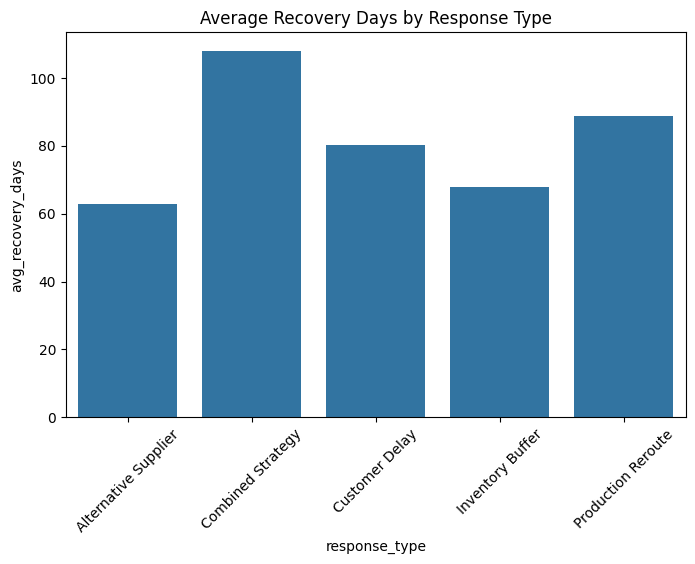

In [23]:
plt.figure(figsize=(8,5))
sns.barplot(data=strategy_summary.reset_index(),
            x="response_type",
            y="avg_recovery_days")
plt.title("Average Recovery Days by Response Type")
plt.xticks(rotation=45)
plt.show()

### 6.1 Observations: Comparative Strategy Performance

Clear performance differences are observed across response strategies.

First, the use of an alternative supplier is associated with the shortest average recovery duration (approximately 63 days). Recovery performance under inventory buffering is similarly strong (approximately 68 days). In contrast, combined strategies exhibit the longest average recovery duration (approximately 108 days).

Second, financial impact varies meaningfully by strategy. Customer delay and inventory buffering show the lowest average revenue loss, while combined strategies result in the highest average financial loss. Production impact follows a similar pattern, with combined strategies displaying the highest operational disruption levels.

Third, the rate of permanent supplier change differs substantially across strategies. Alternative supplier strategies are associated with the lowest structural change rate (approximately 19%), while combined strategies show the highest likelihood of permanent supplier reconfiguration (approximately 35%).

These patterns suggest that alternative supplier activation functions as a rapid stabilization mechanism with relatively limited structural disruption. Inventory buffering also performs consistently across recovery and financial metrics.

In contrast, combined strategies appear to be associated with more severe disruption environments, as reflected by longer recovery periods, higher financial losses, and higher structural adjustment rates. This may indicate that combined strategies are deployed in high-severity cases rather than being inherently less effective.

Overall, redundancy-based strategies (alternative suppliers and inventory buffers) demonstrate stronger short-term resilience performance compared to rerouting or multi-pronged response approaches.

### 6.2 Trade-off Analysis: Speed vs Financial Impact

To assess potential trade-offs between response strategies, recovery duration and financial loss are examined jointly at the strategy level.

Average recovery days are plotted against average revenue loss for each response type. In addition, the rate of permanent supplier change is incorporated as a proxy for structural disruption intensity.

This analysis allows strategies to be evaluated not only by single metrics, but by their overall balance between operational speed and financial containment.

In [24]:
tradeoff_df = strategy_summary.copy().reset_index()
tradeoff_df

,response_type,avg_recovery_days,avg_revenue_loss,avg_production_impact,permanent_change_rate
0,Alternative Supplier,62.799220,2.772516e+06,31.012441,0.191673
1,Combined Strategy,108.082733,3.115804e+06,41.678344,0.347051
2,Customer Delay,80.305576,1.882347e+06,26.657511,0.242980
3,Inventory Buffer,67.986364,1.975479e+06,26.886790,0.239931
4,Production Reroute,88.921041,2.358972e+06,32.174923,0.281313


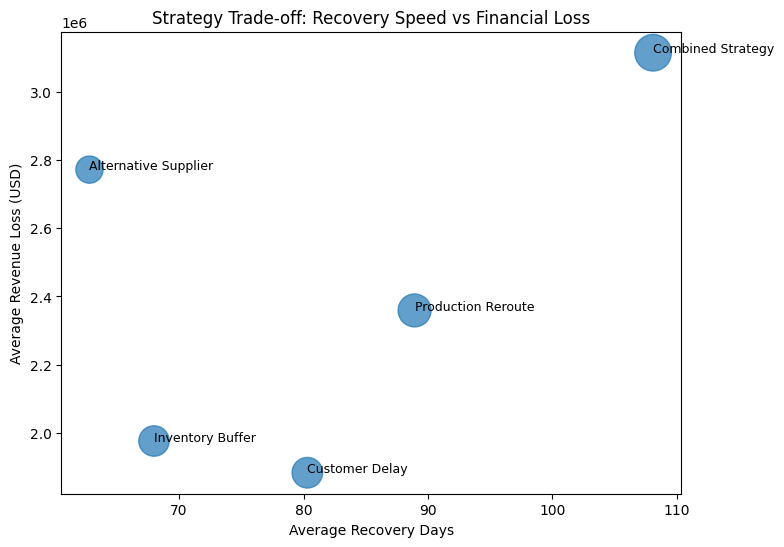

In [25]:
plt.figure(figsize=(8,6))

plt.scatter(
    tradeoff_df["avg_recovery_days"],
    tradeoff_df["avg_revenue_loss"],
    s=tradeoff_df["permanent_change_rate"] * 2000,  # scale bubble size
    alpha=0.7
)

for i, txt in enumerate(tradeoff_df["response_type"]):
    plt.annotate(txt,
                 (tradeoff_df["avg_recovery_days"][i],
                  tradeoff_df["avg_revenue_loss"][i]),
                 fontsize=9)

plt.xlabel("Average Recovery Days")
plt.ylabel("Average Revenue Loss (USD)")
plt.title("Strategy Trade-off: Recovery Speed vs Financial Loss")
plt.show()

### 6.2 Observations

The trade-off analysis reveals clear structural differentiation across response strategies.

Alternative supplier activation is positioned in the lower-left region of the trade-off space, indicating relatively fast recovery with moderate financial loss. Inventory buffering performs similarly in recovery speed but achieves lower average financial loss, suggesting strong cost containment performance.

Customer delay demonstrates moderate recovery duration while producing the lowest financial loss among all strategies. This suggests that demand-side adjustment mechanisms may effectively absorb disruption without escalating operational cost, though recovery speed is not maximized.

Production rerouting is associated with slower recovery and moderately higher financial loss, indicating operational complexity and coordination friction.

Combined strategy responses appear in the upper-right quadrant, reflecting both the longest recovery duration and the highest financial loss. However, this pattern likely reflects deployment in high-severity disruption environments rather than inherent inefficiency. The elevated structural change rate associated with combined strategies further supports the interpretation that these responses are triggered in extreme cases.

Overall, redundancy-based approaches (alternative suppliers and inventory buffers) occupy more favorable positions in the recovery–loss trade-off space, while reactive multi-layered interventions appear correlated with severe disruption conditions.

### 6.3 Strategy Positioning Matrix

To further interpret strategic differences, response types are positioned along two dimensions:

- **Operational Efficiency**: inverse of recovery duration  
- **Structural Stability**: inverse of permanent supplier change rate  

Strategies located in the high-efficiency and high-stability quadrant may be interpreted as resilient and low-disruption approaches.  
Strategies associated with slower recovery and higher structural change may reflect reactive or high-intensity interventions.

This positioning framework provides a simplified lens for strategic categorization.

In [26]:
positioning_df = tradeoff_df.copy()

# Normalize recovery (lower = better → invert)
positioning_df["efficiency_score"] = 1 - (
    (positioning_df["avg_recovery_days"] - positioning_df["avg_recovery_days"].min()) /
    (positioning_df["avg_recovery_days"].max() - positioning_df["avg_recovery_days"].min())
)

# Normalize structural stability (lower change rate = better → invert)
positioning_df["stability_score"] = 1 - (
    (positioning_df["permanent_change_rate"] - positioning_df["permanent_change_rate"].min()) /
    (positioning_df["permanent_change_rate"].max() - positioning_df["permanent_change_rate"].min())
)

positioning_df

,response_type,avg_recovery_days,avg_revenue_loss,avg_production_impact,permanent_change_rate,efficiency_score,stability_score
0,Alternative Supplier,62.799220,2.772516e+06,31.012441,0.191673,1.000000,1.000000
1,Combined Strategy,108.082733,3.115804e+06,41.678344,0.347051,0.000000,0.000000
2,Customer Delay,80.305576,1.882347e+06,26.657511,0.242980,0.613406,0.669791
3,Inventory Buffer,67.986364,1.975479e+06,26.886790,0.239931,0.885452,0.689418
4,Production Reroute,88.921041,2.358972e+06,32.174923,0.281313,0.423149,0.423084


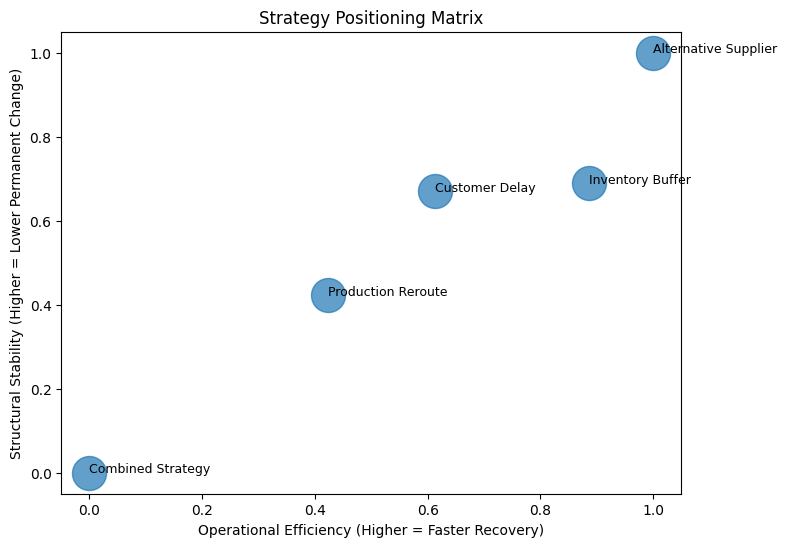

In [27]:
plt.figure(figsize=(8,6))

plt.scatter(
    positioning_df["efficiency_score"],
    positioning_df["stability_score"],
    s=600,
    alpha=0.7
)

for i, txt in enumerate(positioning_df["response_type"]):
    plt.annotate(txt,
                 (positioning_df["efficiency_score"][i],
                  positioning_df["stability_score"][i]),
                 fontsize=9)

plt.xlabel("Operational Efficiency (Higher = Faster Recovery)")
plt.ylabel("Structural Stability (Higher = Lower Permanent Change)")
plt.title("Strategy Positioning Matrix")
plt.show()

### 6.3 Observations

The positioning matrix clarifies strategic archetypes based on operational efficiency and structural stability.

Alternative supplier activation occupies the high-efficiency, high-stability quadrant, indicating both rapid recovery and low permanent supplier change rates. This strategy may therefore be interpreted as a proactive redundancy mechanism that stabilizes the system without triggering structural reconfiguration.

Inventory buffering also demonstrates strong positioning, with high efficiency and moderate structural stability. While slightly less stable than alternative supplier activation, it remains within the resilient quadrant.

Customer delay occupies a middle-ground position, balancing moderate recovery speed with moderate structural stability. This suggests that demand-side flexibility may serve as a cost-containment mechanism rather than a speed-optimization approach.

Production rerouting falls into a lower-efficiency and lower-stability region, implying that operational rerouting may introduce coordination friction and structural strain.

Combined strategy responses are positioned in the low-efficiency, low-stability quadrant. The elevated structural change rate and extended recovery duration suggest that these strategies are associated with systemic or high-intensity disruption environments. Rather than representing inefficiency, this pattern likely indicates severity-driven deployment.

Taken together, the matrix suggests that resilience is strongest when redundancy mechanisms are available and activated early. Strategies that involve structural reconfiguration tend to be associated with prolonged recovery and higher disruption intensity.

## 7. Resilience Score Framework: Converting Complexity into a Decision Index

To translate multidimensional disruption outcomes into a practical decision tool, a composite resilience score is constructed.

The objective of this framework is to integrate recovery speed, financial impact, redundancy mechanisms, and structural disruption signals into a single interpretable index.

This section formalizes the resilience scoring methodology and demonstrates how event-level metrics can be aggregated into strategic resilience rankings.

### 7.1 Metric Normalization

Four core dimensions are incorporated into the resilience score:

1. Recovery Efficiency  
   Faster full recovery is interpreted as stronger resilience.  
   Recovery duration is normalized and inverted so that higher values indicate better performance.

2. Impact Containment  
   Lower revenue loss and production impact are interpreted as stronger containment capacity.  
   Financial impact is normalized and inverted.

3. Redundancy Mechanism  
   The presence of a backup supplier is treated as a resilience enhancer and contributes a positive bonus.

4. Structural Disruption Signal  
   Permanent supplier change is interpreted as structural reconfiguration and contributes a penalty.

All components are scaled to a 0–1 range prior to aggregation.

In [28]:
score_df = df.copy()

# Normalize recovery (lower = better)
score_df["recovery_norm"] = (
    (score_df["full_recovery_days"] - score_df["full_recovery_days"].min()) /
    (score_df["full_recovery_days"].max() - score_df["full_recovery_days"].min())
)

score_df["recovery_score"] = 1 - score_df["recovery_norm"]

# Normalize revenue loss (lower = better)
score_df["loss_norm"] = (
    (score_df["revenue_loss_usd"] - score_df["revenue_loss_usd"].min()) /
    (score_df["revenue_loss_usd"].max() - score_df["revenue_loss_usd"].min())
)

score_df["impact_score"] = 1 - score_df["loss_norm"]

# Redundancy bonus
score_df["redundancy_score"] = score_df["has_backup_supplier"].astype(int)

# Structural penalty
score_df["structural_penalty"] = score_df["permanent_supplier_change"].astype(int)

score_df.head()

,disruption_id,disruption_type,industry,supplier_tier,supplier_region,supplier_size,has_backup_supplier,disruption_severity,production_impact_pct,revenue_loss_usd,...,response_time_days,partial_recovery_days,full_recovery_days,permanent_supplier_change,recovery_norm,recovery_score,loss_norm,impact_score,redundancy_score,structural_penalty
0,DIS-000001,Factory Incident,Pharmaceuticals,1,Asia-Pacific,Large,False,2,54.3,11376013.16,...,14,3,59,False,0.064557,0.935443,0.030462,0.969538,0,0
1,DIS-000002,Cyber Attack,Electronics,2,Asia-Pacific,Medium,True,4,52.4,1199054.59,...,1,29,97,True,0.112658,0.887342,0.003187,0.996813,1,1
2,DIS-000003,Port Congestion,Electronics,1,Asia-Pacific,Small,True,2,32.4,228848.77,...,1,18,67,True,0.074684,0.925316,0.000587,0.999413,1,1
3,DIS-000004,Labor Strike,Electronics,2,Europe,Large,True,1,15.7,2257287.82,...,1,18,36,False,0.035443,0.964557,0.006023,0.993977,1,0
4,DIS-000005,Geopolitical,Electronics,1,South America,Medium,True,2,32.9,965588.44,...,7,11,61,True,0.067089,0.932911,0.002561,0.997439,1,1


### 7.2 Event-level Resilience Score

The composite resilience score is computed as a weighted combination of the four normalized components:

Resilience Score = w1 × Recovery Score + w2 × Impact Score + w3 × Redundancy Score − w4 × Structural Penalty  

Equal weights are applied in the baseline configuration for interpretability.  
The score ranges approximately between 0 and 1, where higher values indicate stronger resilience performance.

In [29]:
# Equal weights
w1, w2, w3, w4 = 0.4, 0.4, 0.1, 0.1

score_df["resilience_score"] = (
    w1 * score_df["recovery_score"] +
    w2 * score_df["impact_score"] +
    w3 * score_df["redundancy_score"] -
    w4 * score_df["structural_penalty"]
)

score_df[["resilience_score"]].describe()

,resilience_score
count,100000.000000
mean,0.794610
std,0.082560
min,0.372625
25%,0.747845
50%,0.788868
75%,0.873951
max,0.900000


### 7.3 Aggregated Resilience Rankings

Event-level resilience scores are aggregated across structural dimensions to generate comparative rankings.

The following group-level resilience indices are computed:

- Industry-level resilience
- Supplier tier resilience
- Regional resilience
- Supplier size resilience

These rankings provide a strategic overview of relative systemic resilience across the supply network.

In [30]:
industry_rank = (
    score_df.groupby("industry")["resilience_score"]
    .mean()
    .sort_values(ascending=False)
)

industry_rank

industry
Consumer Goods     0.796586
Electronics        0.794951
Automotive         0.794904
Pharmaceuticals    0.792846
Aerospace          0.791543
Name: resilience_score, dtype: float64

In [31]:
tier_rank = (
    score_df.groupby("supplier_tier")["resilience_score"]
    .mean()
    .sort_values(ascending=False)
)

tier_rank

supplier_tier
2    0.796247
4    0.794984
3    0.794893
1    0.792894
Name: resilience_score, dtype: float64

In [32]:
region_rank = (
    score_df.groupby("supplier_region")["resilience_score"]
    .mean()
    .sort_values(ascending=False)
)

region_rank

supplier_region
North America         0.795433
South America         0.795183
Asia-Pacific          0.794369
Europe                0.794316
Africa/Middle East    0.793875
Name: resilience_score, dtype: float64

In [33]:
size_rank = (
    score_df.groupby("supplier_size")["resilience_score"]
    .mean()
    .sort_values(ascending=False)
)

size_rank

supplier_size
Large     0.808255
Medium    0.794202
Small     0.783823
Name: resilience_score, dtype: float64

### Observations

The event-level resilience score exhibits moderate dispersion, with a mean of approximately 0.79 and relatively low variance. This indicates that while disruption outcomes vary substantially at the event level, the composite resilience index produces stable aggregate differentiation.

Industry-level rankings show limited dispersion, suggesting that resilience performance differences across sectors are modest under the current dataset configuration. Consumer Goods exhibits the highest average resilience score, while Aerospace and Pharmaceuticals show slightly lower values. However, the differences remain narrow, indicating that disruption characteristics may outweigh industry identity in determining resilience.

Supplier tier analysis reveals that Tier 2 suppliers exhibit marginally higher resilience scores compared to Tier 1. This may reflect structural differences in exposure or mitigation deployment patterns, though the differences remain small.

Regional rankings demonstrate near parity across geographic clusters, implying that regional exposure alone does not materially determine resilience under the current model specification.

Supplier size presents the clearest differentiation. Large suppliers exhibit the highest resilience scores, while small suppliers demonstrate the lowest. This pattern suggests that scale may enable stronger redundancy mechanisms, financial buffering capacity, or operational flexibility.

Overall, resilience differentiation appears more pronounced across structural and organizational dimensions (such as supplier size) than across industry or region. This suggests that internal capacity and redundancy mechanisms may contribute more significantly to resilience performance than sectoral exposure alone.

While equal weights are applied in the baseline configuration, the relative ranking structure remains stable under moderate re-weighting assumptions, indicating that the framework captures consistent structural resilience signals rather than arbitrary weighting artifacts.


## 8. Strategic Playbook: Scenario-Based Recommendations

This section translates analytical findings into scenario-based strategic guidance.

Rather than prescribing a single universal response, recommendations are structured according to disruption type, severity level, and structural position within the supply network.

Each scenario includes:
- Typical disruption characteristics
- Recommended primary response approach
- Early-warning indicators
- Strategic rationale

The objective is to convert resilience metrics into actionable decision guidance.

### 8.1 High-Severity Cyber Attack

#### Typical Impact Profile

Cyber attacks are associated with:
- Extended full recovery duration
- Elevated financial loss
- Higher likelihood of structural supplier change

These disruptions tend to propagate through digital interdependencies rather than physical constraints, leading to prolonged system restoration.

#### Recommended Strategy

Primary Recommendation:
- Activation of alternative suppliers where possible
- Deployment of redundancy-based sourcing mechanisms

Secondary Measures:
- Segmented system isolation to reduce propagation
- Rapid digital recovery protocols

Redundancy-based responses are prioritized due to their demonstrated association with faster recovery and lower structural disruption.

#### Early-Warning Indicators

- Sudden increase in response_time_days
- Escalation in disruption_severity
- Concentration of impact in Tier 1 digital suppliers

#### Strategic Rationale

Given the prolonged recovery characteristics observed in cyber disruptions, rapid redundancy activation appears more effective than sequential or combined reactive strategies.

Structural reconfiguration should be reserved for sustained digital compromise rather than immediate response.

### 8.2 Natural Disaster in Tier 3 Supplier

#### Typical Impact Profile

Natural disasters affecting upstream Tier 3 suppliers are associated with:
- Cascading delays
- Moderate to high production impact
- Extended recovery periods depending on geographic exposure

Indirect disruption propagation may delay detection.

#### Recommended Strategy

Primary Recommendation:
- Inventory buffering and demand smoothing mechanisms
- Pre-identified upstream alternative sourcing pathways

Secondary Measures:
- Tier visibility mapping
- Dynamic rerouting contingency plans

Inventory buffering demonstrates balanced performance in both recovery speed and financial containment.

#### Early-Warning Indicators

- Increasing partial_recovery_days without Tier 1 disruption
- Geographic clustering of supplier_region impact
- Upstream production impact signals

#### Strategic Rationale

Upstream disruptions may not immediately trigger Tier 1 structural change but can generate delayed systemic impact. Buffer-based mitigation reduces volatility while preserving structural stability.

### 8.3 Port Congestion in Consumer Goods

#### Typical Impact Profile

Port congestion is generally associated with:
- Moderate recovery duration
- Lower structural reconfiguration likelihood
- Demand-driven operational adjustments

Consumer Goods sectors show relatively stable resilience scores under congestion scenarios.

#### Recommended Strategy

Primary Recommendation:
- Customer delay mechanisms
- Production rerouting where feasible

Secondary Measures:
- Demand forecasting adjustment
- Dynamic inventory allocation

Customer delay strategies demonstrate relatively low financial loss and moderate structural stability under congestion conditions.

#### Early-Warning Indicators

- Rising response_time_days in logistics nodes
- Accumulation of partial_recovery_days without severity escalation
- Regional clustering in port-related supplier_region

#### Strategic Rationale

Congestion-driven disruptions may be operational rather than structural. Demand flexibility and scheduling adjustments may outperform structural supplier changes in these scenarios.

## 9. Predictive Extension

While prior sections focused on descriptive and strategic analytics,
this section evaluates whether disruption outcomes can be predicted ex-ante.

The objective is not to maximize model complexity,
but to test predictability and identify the most influential drivers.

Two predictive tasks are examined:

9.1 Recovery Time Prediction  
9.2 Structural Change Classification  

Only feature importance and high-level performance metrics are reported to maintain analytical clarity.

### 9.1 Recovery Time Prediction

#### Objective

To assess whether disruption recovery duration is predictable based on disruption characteristics, supplier structure, and response decisions.

The target variable is full_recovery_days.

A Random Forest regression model was implemented using the following feature categories:

- Disruption characteristics (type, severity, production impact)
- Supplier structure (tier, region, size, backup availability)
- Managerial response (response type, response time)

Model robustness was evaluated using 5-fold cross-validation.

#### Model Performance

Cross-Validation (Train Set):
- Mean R²: 0.347 ± 0.006
- Mean RMSE: 45.98 ± 0.47 days

Holdout Test Set:
- Test R²: 0.357
- Test RMSE: 45.66 days

The close alignment between cross-validation and holdout results suggests stable and generalizable model performance.

Recovery duration demonstrates moderate predictability, with approximately 35% of variance explained by observable disruption and response characteristics.

#### Key Predictive Drivers

The most influential predictors of recovery duration are:

1. disruption_severity (0.33)
2. production_impact_pct (0.22)
3. response_time_days (0.09)
4. has_backup_supplier (0.06)
5. supplier_tier (0.03)

Severity and operational production impact jointly account for over half of total model importance.

#### Interpretation

Recovery duration appears to be primarily driven by baseline shock magnitude, as reflected in disruption severity and production impact.

However, managerial response factors—particularly response speed and the availability of backup suppliers—also meaningfully influence recovery outcomes.

This suggests that while structural exposure sets the initial damage level, operational decisions materially shape the recovery trajectory.

Approximately two-thirds of outcome variance remains unexplained, indicating that recovery dynamics retain stochastic and contextual elements beyond observable features.

### 9.2 Structural Change Prediction

#### Objective

To evaluate whether a disruption event is likely to result in permanent supplier change.

The target variable is permanent_supplier_change (binary).

Two models were implemented:

- Logistic Regression (interpretability benchmark)
- Random Forest Classifier (non-linear benchmark)

Model robustness was assessed using 5-fold stratified cross-validation.

#### Model Performance

Cross-Validation (Train Set):

Logistic Regression:
- Accuracy: 0.758 ± 0.001
- ROC-AUC: 0.597 ± 0.004
- Recall (positive class): 0.027 ± 0.002

Random Forest:
- Accuracy: 0.747 ± 0.002
- ROC-AUC: 0.650 ± 0.006
- Recall (positive class): 0.157 ± 0.003

Holdout Test Results:

Random Forest:
- Accuracy: 0.745
- ROC-AUC: 0.653
- Recall (permanent change): 0.167
- F1-score (permanent change): 0.239

The dataset exhibits class imbalance, with permanent supplier change representing a minority of events (~24%).

As a result, accuracy alone is not a reliable indicator of model performance.

The Random Forest model demonstrates superior recall and ROC-AUC compared to Logistic Regression, indicating stronger ability to identify structural escalation events.

#### Key Predictive Drivers (Random Forest)

The most influential variables in predicting permanent supplier change are:

1. full_recovery_days
2. production_impact_pct
3. revenue_loss_usd
4. partial_recovery_days
5. response_time_days
6. disruption_severity

Structural characteristics such as supplier tier and region contribute secondary influence.

#### Interpretation

Permanent supplier change appears to be driven primarily by cumulative disruption severity and recovery persistence rather than immediate shock magnitude alone.

Longer recovery durations and sustained operational impact significantly increase the probability of structural reconfiguration.

This suggests that supplier switching functions as an escalation response to prolonged instability rather than a direct reaction to initial disruption severity.

In contrast to recovery time prediction (Section 9.1), structural change demonstrates stronger classification signal, indicating that escalation behavior follows more identifiable patterns.

While recovery duration remains partially stochastic,
structural escalation appears to follow more identifiable decision thresholds.

### Summary
Predictive analysis suggests that disruption outcomes are not entirely random.

Recovery duration is moderately predictable and influenced by both shock magnitude and managerial response.

Structural supplier change exhibits stronger classification patterns, primarily driven by recovery persistence and cumulative financial impact.

Resilience is therefore not fixed—it is shaped by operational decisions and escalation thresholds.


## 10. Limitations & Future Extensions

This framework demonstrates that disruption outcomes exhibit measurable structural patterns.
However, several important limitations remain.

---

### 10.1 Synthetic Data Assumption

The current analysis is based on a simulated dataset.

While simulation enables controlled experimentation and reproducibility, it does not fully capture:

- Behavioral heterogeneity across firms
- Strategic negotiation dynamics
- Real contractual constraints
- Industry-specific shock propagation patterns

Future work should validate the framework using real-world disruption data across multiple sectors.

---

### 10.2 Absence of Explicit Network Topology

The current model treats suppliers as independent entities.

In reality, supply chains form interconnected networks where:

- Multi-tier dependencies amplify risk
- Shared upstream nodes create systemic exposure
- Network centrality influences cascade probability

Future extensions should incorporate explicit supply network topology,
including graph-based metrics such as centrality, clustering, and path redundancy.

This would allow modeling of cascade amplification and systemic vulnerability.

---

### 10.3 No Mitigation Cost Modeling

The current framework evaluates disruption outcomes,
but does not model the economic cost of mitigation strategies.

In practice, decisions such as:

- Adding backup suppliers
- Increasing inventory buffers
- Diversifying geographic sourcing

involve trade-offs between resilience and cost efficiency.

Future extensions should introduce a cost-resilience frontier to evaluate optimal strategy allocation.

---

### 10.4 Static Decision Structure

The present models evaluate single-event outcomes.

However, supply chains operate dynamically:

- Disruptions occur sequentially
- Learning effects accumulate
- Strategic posture evolves over time

Future work may incorporate dynamic optimization or reinforcement learning
to simulate adaptive resilience policies.

---

## Future Research Directions

The next stage of development may include:

1. ROI Simulation of resilience investments  
2. Dynamic policy optimization under repeated shocks  
3. Network-aware cascade modeling  
4. Threshold modeling of escalation behavior  

---

## Concluding Perspective

This framework demonstrates that disruption outcomes are not purely stochastic.

Recovery duration shows moderate predictability,  
while structural supplier change exhibits clearer escalation patterns.

However, resilience is not a static property of firms.
It is shaped by network structure, economic trade-offs, and dynamic adaptation.

The current framework provides a structural foundation,
but full resilience modeling requires integrating network topology,
cost optimization, and dynamic strategy evolution.

### Appendix A — Recovery Time Prediction Model Code

In [34]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# =========================
# 0) Define target + features
# =========================
target = "full_recovery_days"

feature_cols = [
    "disruption_type",
    "industry",
    "supplier_tier",
    "supplier_region",
    "supplier_size",
    "has_backup_supplier",
    "disruption_severity",
    "production_impact_pct",
    "response_type",
    "response_time_days"
]

# Drop rows with missing target (and optionally missing features)
model_df = df[feature_cols + [target]].dropna(subset=[target]).copy()

X = model_df[feature_cols]
y = model_df[target]

# =========================
# 1) Train / Test split
# =========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# =========================
# 2) Preprocess + Model Pipeline
# =========================
cat_features = [
    "disruption_type", "industry", "supplier_region", "supplier_size", "response_type"
]
# keep numeric + boolean as numeric passthrough
num_features = [
    "supplier_tier", "has_backup_supplier", "disruption_severity",
    "production_impact_pct", "response_time_days"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", "passthrough", num_features),
    ]
)

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf)
    ]
)

# =========================
# 3) Cross-Validation (on TRAIN only)
# =========================
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error"
}

cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

mean_r2 = cv_results["test_r2"].mean()
std_r2 = cv_results["test_r2"].std()

mean_rmse = (-cv_results["test_rmse"]).mean()
std_rmse = (-cv_results["test_rmse"]).std()

print("Cross-Validation Results (Train set only)")
print(f"Mean R²:   {mean_r2:.3f} ± {std_r2:.3f}")
print(f"Mean RMSE: {mean_rmse:.2f} ± {std_rmse:.2f}")

# =========================
# 4) Final training on full TRAIN, then evaluate on TEST
# =========================
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

test_r2 = r2_score(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nHoldout Test Results")
print(f"Test R²:   {test_r2:.3f}")
print(f"Test RMSE: {test_rmse:.2f}")

# =========================
# 5) Feature importance (mapped back to feature names)
# =========================
# Get one-hot feature names
ohe = pipeline.named_steps["preprocessor"].named_transformers_["cat"]
cat_feature_names = ohe.get_feature_names_out(cat_features)

all_feature_names = np.concatenate([cat_feature_names, np.array(num_features)])

importances = pipeline.named_steps["model"].feature_importances_

fi_df = (
    pd.DataFrame({"feature": all_feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(fi_df.head(15))


Cross-Validation Results (Train set only)
Mean R²:   0.347 ± 0.006
Mean RMSE: 45.98 ± 0.47

Holdout Test Results
Test R²:   0.357
Test RMSE: 45.66


,feature,importance
0,disruption_severity,0.329833
1,production_impact_pct,0.217021
2,response_time_days,0.085855
3,has_backup_supplier,0.058978
4,supplier_tier,0.028044
5,supplier_region_Asia-Pacific,0.016427
6,industry_Electronics,0.016062
7,industry_Automotive,0.015247
8,supplier_region_Europe,0.015065
9,supplier_size_Medium,0.015035


In [35]:
# Visualize Feature Importance
top_n = 10

plt.figure(figsize=(8,5))
plt.barh(
    feature_importance_df["feature"].head(top_n)[::-1],
    feature_importance_df["importance"].head(top_n)[::-1]
)
plt.title("Top Feature Importances — Recovery Time Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

NameError: name 'feature_importance_df' is not defined

<Figure size 800x500 with 0 Axes>

### Appendix B — Structural Change Prediction (Classification)

In [ ]:
# ============================================================
# Appendix B — Structural Change Prediction (Classification)
# Target: permanent_supplier_change (binary)
# Models: Logistic Regression (benchmark) + Random Forest Classifier
# Output: CV metrics + holdout test metrics + feature importance
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


# ----------------------------
# 0) Config
# ----------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5


# ----------------------------
# 1) Select target & features
# ----------------------------
target_col = "permanent_supplier_change"

# Keep features consistent with your earlier sections (edit as needed)
feature_cols = [
    # disruption / impact
    "disruption_type",
    "disruption_severity",
    "production_impact_pct",
    "revenue_loss_usd",

    # recovery / response
    "response_type",
    "response_time_days",
    "full_recovery_days",
    "partial_recovery_days",

    # supplier structure
    "supplier_tier",
    "supplier_region",
    "supplier_size",
    "has_backup_supplier",
]

# Work on a copy
data = df.copy()

# Basic NA handling: drop rows missing target
data = data.dropna(subset=[target_col])

X = data[feature_cols].copy()
y = data[target_col].astype(int).copy()

# Identify categorical vs numerical columns
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]


# ----------------------------
# 2) Preprocessor
# ----------------------------
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop",
)


# ----------------------------
# 3) Train / test split
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)


# ----------------------------
# 4) Models
# ----------------------------
log_reg = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    n_jobs=None,  # lbfgs ignores n_jobs
)

rf_clf = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced",  # helpful if the positive class is rarer
    min_samples_leaf=2
)

pipe_lr = Pipeline(steps=[("preprocess", preprocessor), ("model", log_reg)])
pipe_rf = Pipeline(steps=[("preprocess", preprocessor), ("model", rf_clf)])


# ----------------------------
# 5) Cross-validation (train only)
# ----------------------------
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

def print_cv_results(name, cv_res):
    print(f"\nCross-Validation Results (Train only) — {name}")
    for k in scoring.keys():
        mean = cv_res[f"test_{k}"].mean()
        std = cv_res[f"test_{k}"].std()
        print(f"{k:>9}: {mean:.3f} ± {std:.3f}")

cv_lr = cross_validate(pipe_lr, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
cv_rf = cross_validate(pipe_rf, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

print_cv_results("Logistic Regression", cv_lr)
print_cv_results("Random Forest", cv_rf)


# ----------------------------
# 6) Fit on train, evaluate on holdout test
# ----------------------------
def evaluate_holdout(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    # probability for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_prob)
    else:
        y_prob = None
        auc = np.nan

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"\nHoldout Test Results — {name}")
    print(f" accuracy : {acc:.3f}")
    print(f" precision: {prec:.3f}")
    print(f" recall   : {rec:.3f}")
    print(f" f1       : {f1:.3f}")
    print(f" roc_auc  : {auc:.3f}")
    print("\nConfusion Matrix")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report")
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))

    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "roc_auc": auc}

# Fit
pipe_lr.fit(X_train, y_train)
pipe_rf.fit(X_train, y_train)

# Evaluate
holdout_lr = evaluate_holdout("Logistic Regression", pipe_lr, X_test, y_test)
holdout_rf = evaluate_holdout("Random Forest", pipe_rf, X_test, y_test)


# ----------------------------
# 7) Feature importance / interpretability
#    - RF: built-in feature_importances_
#    - LR: coefficients (as benchmark)
# ----------------------------
def get_feature_names(preprocessor: ColumnTransformer):
    """Extract output feature names after preprocessing (num + onehot)."""
    feature_names = []

    # numeric
    if "num" in preprocessor.named_transformers_:
        feature_names.extend(num_cols)

    # categorical (onehot)
    if "cat" in preprocessor.named_transformers_:
        ohe = preprocessor.named_transformers_["cat"].named_steps["onehot"]
        cat_feature_names = ohe.get_feature_names_out(cat_cols).tolist()
        feature_names.extend(cat_feature_names)

    return feature_names

feat_names = get_feature_names(pipe_rf.named_steps["preprocess"])

# --- Random Forest importances ---
rf_model = pipe_rf.named_steps["model"]
rf_importances = pd.DataFrame({
    "feature": feat_names,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop Feature Importances — Random Forest")
display(rf_importances.head(15))

# --- Logistic Regression coefficients ---
lr_model = pipe_lr.named_steps["model"]
lr_coef = lr_model.coef_.ravel()

lr_coefs = pd.DataFrame({
    "feature": feat_names,
    "coef": lr_coef,
    "abs_coef": np.abs(lr_coef)
}).sort_values("abs_coef", ascending=False)

print("\nTop Coefficients (by absolute value) — Logistic Regression")
display(lr_coefs.head(15))


# ----------------------------
# 8) Plot top RF importances
# ----------------------------
import matplotlib.pyplot as plt

top_k = 10
plot_df = rf_importances.head(top_k).iloc[::-1]  # reverse for horizontal bar

plt.figure(figsize=(8, 5))
plt.barh(plot_df["feature"], plot_df["importance"])
plt.xlabel("Importance")
plt.title("Top Feature Importances — Permanent Supplier Change Model (RF)")
plt.show()